Assignment 53  Decision Tree Classification
Description: Implement a Decision Tree classification model using Python and Scikit-learn. Load a dataset, split it into training and testing sets, train the model, make predictions, evaluate accuracy, display the confusion matrix, and visualize the decision tree.

First five rows:
   mean radius  mean texture  mean perimeter  mean area  mean smoothness  \
0        17.99         10.38          122.80     1001.0          0.11840   
1        20.57         17.77          132.90     1326.0          0.08474   
2        19.69         21.25          130.00     1203.0          0.10960   
3        11.42         20.38           77.58      386.1          0.14250   
4        20.29         14.34          135.10     1297.0          0.10030   

   mean compactness  mean concavity  mean concave points  mean symmetry  \
0           0.27760          0.3001              0.14710         0.2419   
1           0.07864          0.0869              0.07017         0.1812   
2           0.15990          0.1974              0.12790         0.2069   
3           0.28390          0.2414              0.10520         0.2597   
4           0.13280          0.1980              0.10430         0.1809   

   mean fractal dimension  ...  worst radius  worst texture  worst perimete

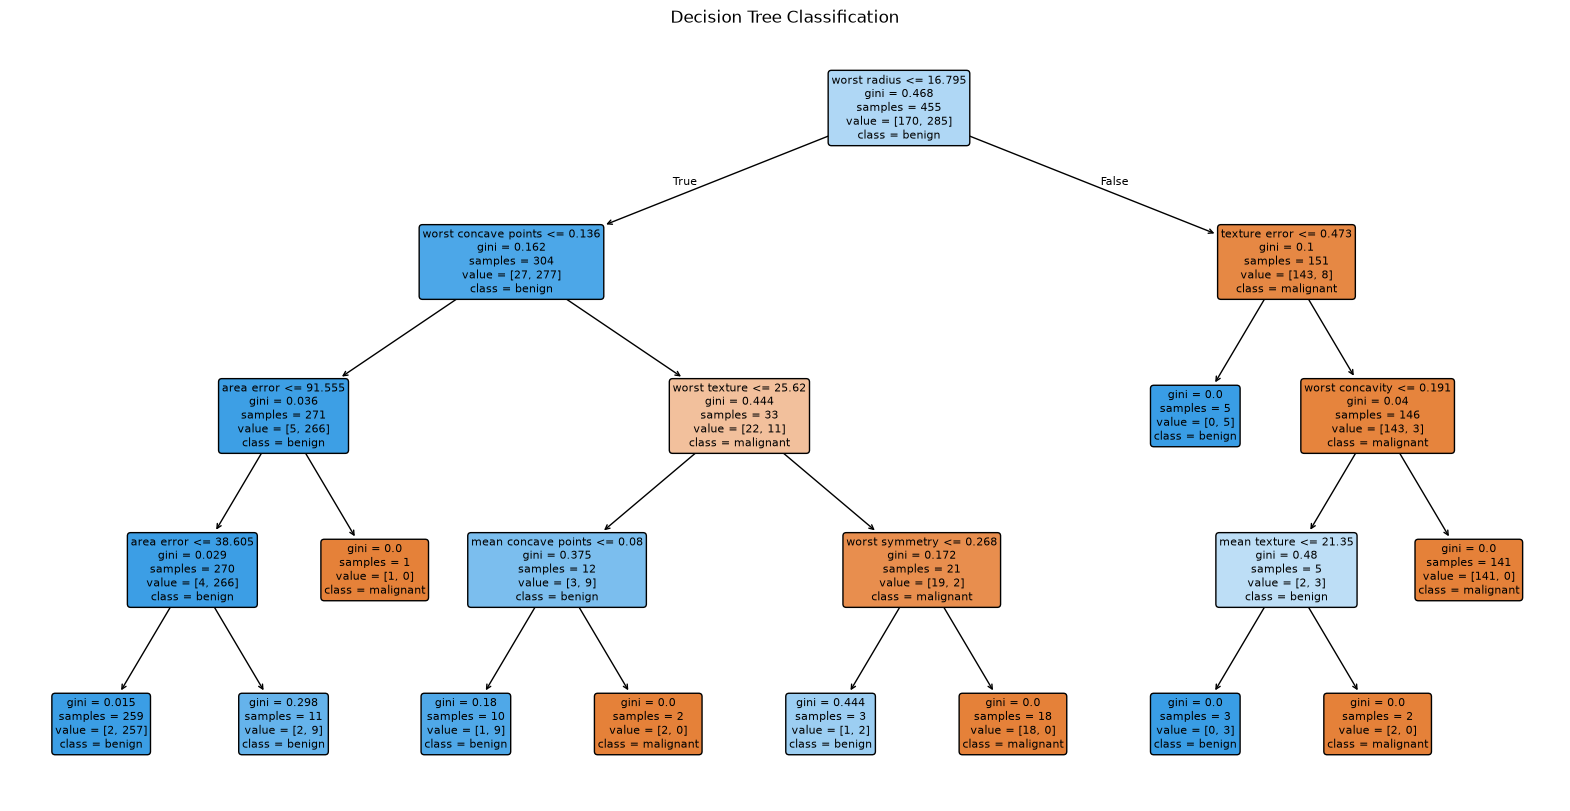

Predicted class: malignant


In [1]:
# Import libraries
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# Load dataset
data = load_breast_cancer()
X = pd.DataFrame(data.data, columns=data.feature_names)
y = data.target

print("First five rows:")
print(X.head())

print("\nDataset shape:", X.shape)

# Split dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# Train model
model = DecisionTreeClassifier(
    criterion="gini",
    max_depth=4,
    random_state=42
)
model.fit(X_train, y_train)

# Predict
y_pred = model.predict(X_test)

# Evaluate
print("\nAccuracy:", accuracy_score(y_test, y_pred))
print("\nClassification Report:")
print(classification_report(y_test, y_pred,
                            target_names=data.target_names))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))

# Visualize decision tree
plt.figure(figsize=(20, 10))
plot_tree(
    model,
    feature_names=data.feature_names,
    class_names=data.target_names,
    filled=True,
    rounded=True
)
plt.title("Decision Tree Classification")
plt.show()

# Predict one sample
sample = X_test.iloc[[0]]
prediction = model.predict(sample)

print("Predicted class:", data.target_names[prediction[0]])

Assignment 54 — Support Vector Machines (SVM)
Description: Implement Support Vector Machine classification using Scikit-learn. Prepare a dataset, split it into training and testing sets, scale the features, train linear and RBF kernel SVM models, compare their performance, and make predictions.

In [2]:
# Import libraries
import pandas as pd
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.svm import SVC
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

# Load dataset
data = load_iris()
X = pd.DataFrame(data.data, columns=data.feature_names)
y = data.target

print("First five rows:")
print(X.head())

print("\nDataset shape:", X.shape)
print("\nTarget classes:", data.target_names)

# Split dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Train Linear SVM
linear_model = make_pipeline(
    StandardScaler(),
    SVC(kernel="linear", C=1.0)
)

linear_model.fit(X_train, y_train)
linear_pred = linear_model.predict(X_test)

print("\nLinear SVM Accuracy:")
print(accuracy_score(y_test, linear_pred))

print("\nLinear SVM Classification Report:")
print(classification_report(
    y_test, linear_pred,
    target_names=data.target_names
))

print("\nLinear SVM Confusion Matrix:")
print(confusion_matrix(y_test, linear_pred))

# Train RBF Kernel SVM
rbf_model = make_pipeline(
    StandardScaler(),
    SVC(kernel="rbf", C=1.0, gamma="scale")
)

rbf_model.fit(X_train, y_train)
rbf_pred = rbf_model.predict(X_test)

print("\nRBF SVM Accuracy:")
print(accuracy_score(y_test, rbf_pred))

print("\nRBF SVM Classification Report:")
print(classification_report(
    y_test, rbf_pred,
    target_names=data.target_names
))

print("\nRBF SVM Confusion Matrix:")
print(confusion_matrix(y_test, rbf_pred))

# Compare models
comparison = pd.DataFrame({
    "Model": ["Linear SVM", "RBF SVM"],
    "Accuracy": [
        accuracy_score(y_test, linear_pred),
        accuracy_score(y_test, rbf_pred)
    ]
})

print("\nModel Comparison:")
print(comparison)

# Predict a sample
sample = X_test.iloc[[0]]
prediction = rbf_model.predict(sample)

print("\nSample:")
print(sample)

print("\nPredicted flower:",
      data.target_names[prediction[0]])
print("Actual flower:",
      data.target_names[y_test.iloc[0]]
      if hasattr(y_test, "iloc")
      else data.target_names[y_test[0]])

First five rows:
   sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)
0                5.1               3.5                1.4               0.2
1                4.9               3.0                1.4               0.2
2                4.7               3.2                1.3               0.2
3                4.6               3.1                1.5               0.2
4                5.0               3.6                1.4               0.2

Dataset shape: (150, 4)

Target classes: ['setosa' 'versicolor' 'virginica']

Linear SVM Accuracy:
1.0

Linear SVM Classification Report:
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       1.00      1.00      1.00        10
   virginica       1.00      1.00      1.00        10

    accuracy                           1.00        30
   macro avg       1.00      1.00      1.00        30
weighted avg       1.00      1.00      1.00        30


Linear

Assignment 55 — Time-Series Analysis with Pandas
Description: Perform time-series analysis using Pandas. Create a time-indexed dataset, convert dates to datetime format, filter date ranges, calculate monthly summaries, visualize trends, calculate rolling averages, and analyze percentage changes.

Libraries imported successfully!

First Five Rows:
        Date       Sales
0 2025-01-01  102.483571
1 2025-01-02  107.291828
2 2025-01-03  113.317392
3 2025-01-04  112.448492
4 2025-01-05   95.149736

Date Data Type:
datetime64[us]

Dataset Information:
<class 'pandas.DataFrame'>
DatetimeIndex: 365 entries, 2025-01-01 to 2025-12-31
Data columns (total 1 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   Sales   365 non-null    float64
dtypes: float64(1)
memory usage: 5.7 KB

Dataset Shape:
(365, 1)

Descriptive Statistics:
            Sales
count  365.000000
mean   130.049732
std     19.509918
min     84.758141
25%    113.945596
50%    129.667062
75%    146.287932
max    173.052239


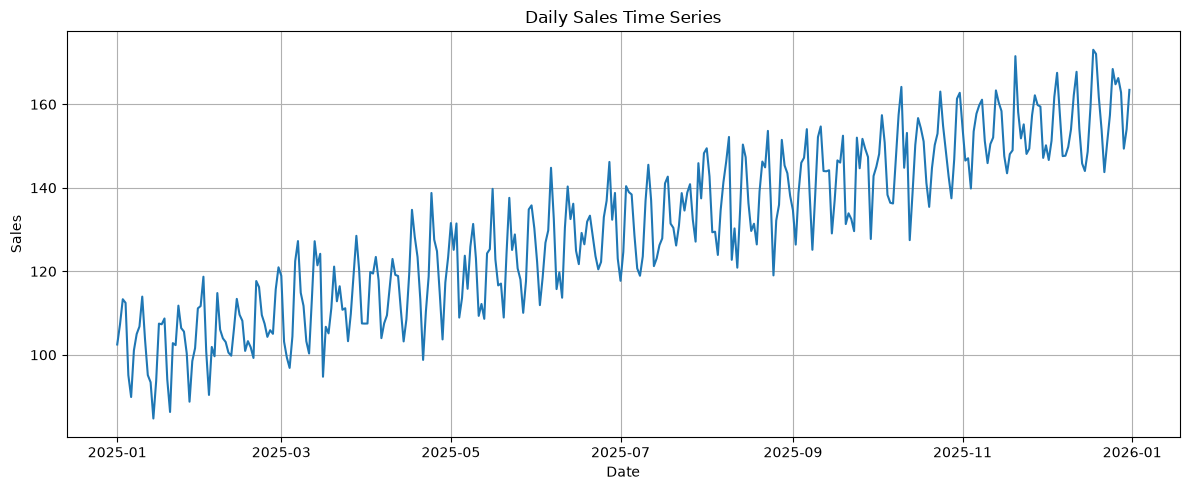


January 2025 Sales:
                 Sales
Date                  
2025-01-01  102.483571
2025-01-02  107.291828
2025-01-03  113.317392
2025-01-04  112.448492
2025-01-05   95.149736
2025-01-06   89.904212
2025-01-07  101.066760
2025-01-08  104.991020
2025-01-09  106.789624
2025-01-10  113.945596
2025-01-11  103.670101
2025-01-12   95.145701
2025-01-13   93.438554
2025-01-14   84.758141
2025-01-15   93.683103
2025-01-16  107.479405
2025-01-17  107.322486
2025-01-18  108.712272
2025-01-19   94.088075
2025-01-20   86.321071
2025-01-21  102.806632
2025-01-22  102.332657
2025-01-23  111.782329
2025-01-24  106.416747
2025-01-25  105.572968
2025-01-26  100.336655
2025-01-27   88.781467
2025-01-28   98.510725
2025-01-29  101.612191
2025-01-30  111.140066
2025-01-31  111.685801

Sales from March 1 to March 7:
                 Sales
Date                  
2025-03-01  118.941838
2025-03-02  103.155401
2025-03-03   99.377371
2025-03-04   96.869791
2025-03-05  104.403582
2025-03-06  122.430394
2025

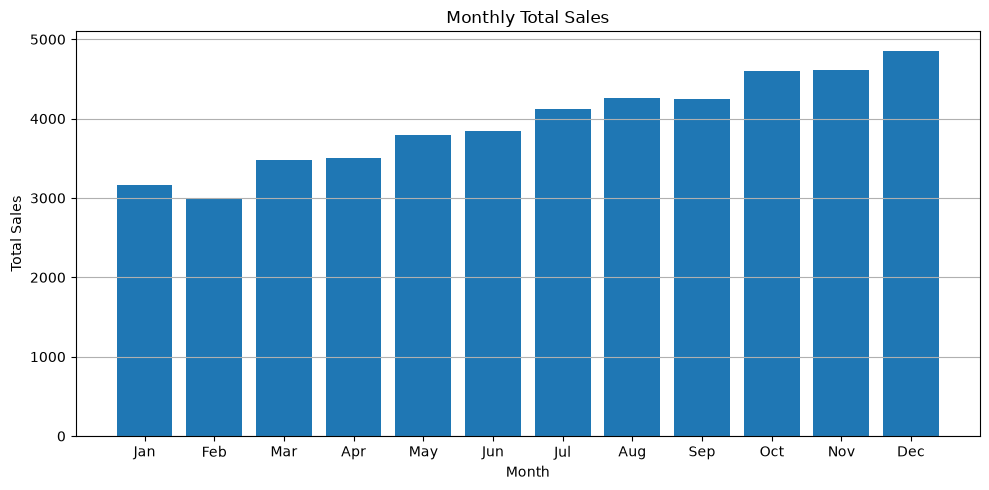


Monthly Average Sales:
Date
2025-01-01    102.03
2025-02-01    106.62
2025-03-01    112.10
2025-04-01    116.86
2025-05-01    122.54
2025-06-01    128.27
2025-07-01    132.80
2025-08-01    137.62
2025-09-01    141.40
2025-10-01    148.36
2025-11-01    153.66
2025-12-01    156.69
Freq: MS, Name: Sales, dtype: float64


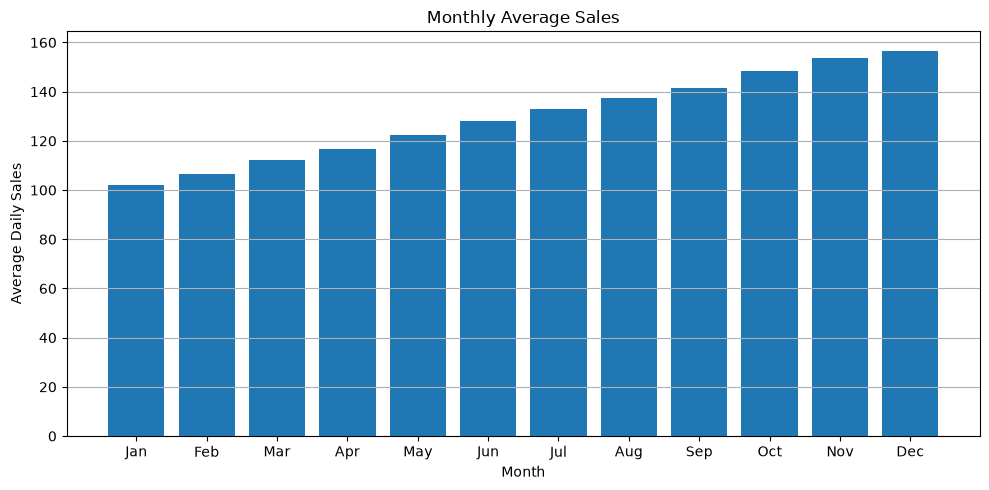


7-Day Rolling Average:
                 Sales  7_Day_Average
Date                                 
2025-01-01  102.483571            NaN
2025-01-02  107.291828            NaN
2025-01-03  113.317392            NaN
2025-01-04  112.448492            NaN
2025-01-05   95.149736            NaN
2025-01-06   89.904212            NaN
2025-01-07  101.066760     103.094570
2025-01-08  104.991020     103.452777
2025-01-09  106.789624     103.381034
2025-01-10  113.945596     103.470777

30-Day Rolling Average:
                 Sales  30_Day_Average
Date                                  
2025-01-01  102.483571             NaN
2025-01-02  107.291828             NaN
2025-01-03  113.317392             NaN
2025-01-04  112.448492             NaN
2025-01-05   95.149736             NaN
2025-01-06   89.904212             NaN
2025-01-07  101.066760             NaN
2025-01-08  104.991020             NaN
2025-01-09  106.789624             NaN
2025-01-10  113.945596             NaN
2025-01-11  103.670101     

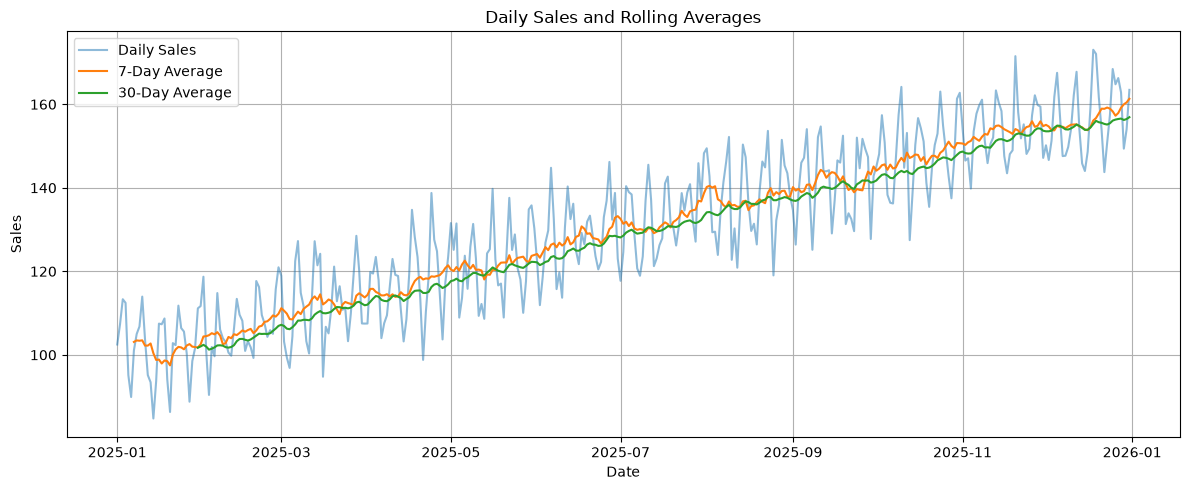


Daily Percentage Change:
             Sales  Percentage_Change
Date                                 
2025-01-01  102.48                NaN
2025-01-02  107.29               4.69
2025-01-03  113.32               5.62
2025-01-04  112.45              -0.77
2025-01-05   95.15             -15.38
2025-01-06   89.90              -5.51
2025-01-07  101.07              12.42
2025-01-08  104.99               3.88
2025-01-09  106.79               1.71
2025-01-10  113.95               6.70

Highest Sales Date:
2025-12-18 00:00:00
Highest Sales Value:
173.05

Lowest Sales Date:
2025-01-14 00:00:00
Lowest Sales Value:
84.76

Monthly Sales Summary:
            Total_Sales  Average_Sales  Minimum_Sales  Maximum_Sales
Date                                                                
2025-01-01      3162.99         102.03          84.76         113.95
2025-02-01      2985.34         106.62          90.40         120.97
2025-03-01      3475.19         112.10          94.76         128.50
2025-04-01    

In [4]:
# ============================================================
# Assignment 55 — Time-Series Analysis with Pandas
# Topic: Machine Learning
# Reference:
# https://www.dataquest.io/blog/tutorial-time-series-analysis-with-pandas/
# ============================================================

# Step 1: Import libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

print("Libraries imported successfully!")


# Step 2: Create sample daily sales dataset

dates = pd.date_range(
    start="2025-01-01",
    periods=365,
    freq="D"
)

np.random.seed(42)

trend = np.linspace(100, 160, 365)

seasonality = 10 * np.sin(
    2 * np.pi * np.arange(365) / 7
)

noise = np.random.normal(0, 5, 365)

sales = trend + seasonality + noise

df = pd.DataFrame({
    "Date": dates,
    "Sales": sales
})

print("\nFirst Five Rows:")
print(df.head())


# Step 3: Convert Date column to datetime

df["Date"] = pd.to_datetime(df["Date"])

print("\nDate Data Type:")
print(df["Date"].dtype)


# Step 4: Set Date as index

df.set_index("Date", inplace=True)

print("\nDataset Information:")
df.info()

print("\nDataset Shape:")
print(df.shape)


# Step 5: Display descriptive statistics

print("\nDescriptive Statistics:")
print(df.describe())


# Step 6: Plot daily sales

plt.figure(figsize=(12, 5))

plt.plot(df.index, df["Sales"])

plt.title("Daily Sales Time Series")
plt.xlabel("Date")
plt.ylabel("Sales")

plt.grid(True)
plt.tight_layout()
plt.show()


# Step 7: Filter January sales

print("\nJanuary 2025 Sales:")
print(df.loc["2025-01"])


# Step 8: Select a specific date range

print("\nSales from March 1 to March 7:")
print(df.loc["2025-03-01":"2025-03-07"])


# Step 9: Calculate monthly total sales

monthly_total = df["Sales"].resample("MS").sum()

print("\nMonthly Total Sales:")
print(monthly_total.round(2))


# Step 10: Plot monthly total sales
# Using bar() avoids the MonthBegin plotting error

plt.figure(figsize=(10, 5))

plt.bar(
    monthly_total.index.strftime("%b"),
    monthly_total.values
)

plt.title("Monthly Total Sales")
plt.xlabel("Month")
plt.ylabel("Total Sales")

plt.grid(axis="y")
plt.tight_layout()
plt.show()


# Step 11: Calculate monthly average sales

monthly_average = df["Sales"].resample("MS").mean()

print("\nMonthly Average Sales:")
print(monthly_average.round(2))


# Step 12: Plot monthly average sales

plt.figure(figsize=(10, 5))

plt.bar(
    monthly_average.index.strftime("%b"),
    monthly_average.values
)

plt.title("Monthly Average Sales")
plt.xlabel("Month")
plt.ylabel("Average Daily Sales")

plt.grid(axis="y")
plt.tight_layout()
plt.show()


# Step 13: Calculate 7-day rolling average

df["7_Day_Average"] = (
    df["Sales"].rolling(window=7).mean()
)

print("\n7-Day Rolling Average:")
print(df[["Sales", "7_Day_Average"]].head(10))


# Step 14: Calculate 30-day rolling average

df["30_Day_Average"] = (
    df["Sales"].rolling(window=30).mean()
)

print("\n30-Day Rolling Average:")
print(df[["Sales", "30_Day_Average"]].head(35))


# Step 15: Plot sales with rolling averages

plt.figure(figsize=(12, 5))

plt.plot(
    df.index,
    df["Sales"],
    label="Daily Sales",
    alpha=0.5
)

plt.plot(
    df.index,
    df["7_Day_Average"],
    label="7-Day Average"
)

plt.plot(
    df.index,
    df["30_Day_Average"],
    label="30-Day Average"
)

plt.title("Daily Sales and Rolling Averages")
plt.xlabel("Date")
plt.ylabel("Sales")

plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


# Step 16: Calculate daily percentage change

df["Percentage_Change"] = (
    df["Sales"].pct_change() * 100
)

print("\nDaily Percentage Change:")
print(df[["Sales", "Percentage_Change"]].head(10).round(2))


# Step 17: Find highest sales

highest_date = df["Sales"].idxmax()
highest_value = df["Sales"].max()

print("\nHighest Sales Date:")
print(highest_date)

print("Highest Sales Value:")
print(round(highest_value, 2))


# Step 18: Find lowest sales

lowest_date = df["Sales"].idxmin()
lowest_value = df["Sales"].min()

print("\nLowest Sales Date:")
print(lowest_date)

print("Lowest Sales Value:")
print(round(lowest_value, 2))


# Step 19: Display monthly summary

monthly_summary = df["Sales"].resample("MS").agg(
    Total_Sales="sum",
    Average_Sales="mean",
    Minimum_Sales="min",
    Maximum_Sales="max"
)

print("\nMonthly Sales Summary:")
print(monthly_summary.round(2))


# Step 20: Final summary

print("\n========== TIME-SERIES ANALYSIS SUMMARY ==========")

print("Total Records:", len(df))

print("Start Date:", df.index.min().date())

print("End Date:", df.index.max().date())

print("Average Sales:", round(df["Sales"].mean(), 2))

print("Total Sales:", round(df["Sales"].sum(), 2))

print("\nMonthly Groups:", len(monthly_summary))

print("\nTime-Series Analysis Completed Successfully!")